# Put freshness in the situation report

**Emergency operations · 15–25 minutes · learning companion**

A global-health field guide connecting monitoring, spatial epidemiology and dated EOC situation reports.

**Learning question:** Does a high-severity signal remain useful when it is stale?

**Source project:** [JupyterLite-World-Monitor-Prototype](https://github.com/jltobias/JupyterLite-World-Monitor-Prototype).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Use an explicit assumed decay rule to compare four fictional signals. This is an inspectable prioritization heuristic, not validated emergency triage.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Fictional signal, severity, age in hours: [('S1', 8, 1), ('S2', 9, 12), ('S3', 5, 2), ('S4', 7, 24)]
Teaching freshness-weighted signal | heuristic score: {'S1': 6.857, 'S2': 3.0, 'S3': 3.75, 'S4': 1.4}


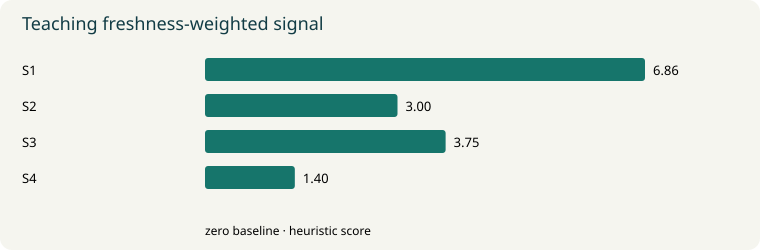

In [2]:
signals = [('S1',8,1), ('S2',9,12), ('S3',5,2), ('S4',7,24)]
priority = {name:severity/(1+age/6) for name,severity,age in signals}
print('Fictional signal, severity, age in hours:', signals)
bars(priority, 'Teaching freshness-weighted signal', 'heuristic score')


## Interpret the result

The freshest signal ranks above a more severe but stale item. A decay constant encodes a judgment and could suppress a slowly developing emergency.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Compare 3-hour and 24-hour decay constants. Add an unverified flag and decide how to represent it without turning unknown into zero.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-World-Monitor-Prototype](https://github.com/jltobias/JupyterLite-World-Monitor-Prototype).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-World-Monitor-Prototype/blob/557e03bb9c3cad560292f5d4bc31deccfd79d570/README.md); inspected 2026-11-01, commit `557e03bb9c3c`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

Source distinguishes optional live USGS/context from bundled samples. External interactive libraries need network; this atlas is not a live monitoring service. Save dated reports with source and uncertainty.

- [Read source Book](https://jltobias.github.io/JupyterLite-World-Monitor-Prototype/book/intro.html) - Read the original project course and its own source notes. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Run source Lab](https://jltobias.github.io/JupyterLite-World-Monitor-Prototype/lab/index.html?path=00_Start_Here.ipynb) - Run the source project notebooks; its dependencies and data terms apply. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
